# 08.05 — Brick 5: Central Story Positions

This notebook is **only Brick 5**.

It does not explain NLP embeddings.  
It does not rebuild the network.  
It does not explain all communities again.  
It does not focus on bridging/betweenness. That comes in Brick 6.

Its job is to answer one reader question:

> What does it mean for a film to be central in a plot-similarity network?

## Thesis-level idea

In this thesis, a central film is **not** automatically:

```text
the most famous film
the best film
the most profitable film
the film with the biggest actors
```

A central film means:

```text
a film strongly embedded in a dense neighborhood of similar stories
```

So this brick explains centrality as **story typicality / narrative embeddedness**.

## Figures produced

```text
outputs/thesis_bricks/05_central_story_positions/figures/
```

1. `01_centrality_as_story_typicality.png`  
2. `02_weighted_degree_explainer.png`  
3. `03_weighted_degree_distribution.png`  
4. `04_central_films_by_community_table.png`  
5. `05_central_story_profile_CXX.png` for selected communities  
6. `06_central_film_local_neighborhood_CXX.png` for selected films  
7. `07_centrality_by_community_small_multiples.png`  
8. `08_centrality_interpretation_summary.png`  

## Design rule

Do not show thousands of points.

Use selected central examples and local neighborhoods so the reader understands the meaning of centrality brick by brick.


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1"
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def fmt_float(x, d=3):
    try:
        return f"{float(x):.{d}f}"
    except Exception:
        return "—"

def detect_edge_cols(df):
    pairs = [("source", "target"), ("source_id", "target_id"), ("src", "dst"), ("u", "v"), ("node1", "node2"), ("from", "to")]
    for a, b in pairs:
        if a in df.columns and b in df.columns:
            return a, b
    return df.columns[0], df.columns[1]

def detect_weight_col(df):
    candidates = []
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in ["weight", "similarity", "cosine", "score"]):
            candidates.append(c)
    return candidates[0] if candidates else None

def parse_examples(s, max_n=5):
    if pd.isna(s):
        return []
    text = str(s)
    parts = re.split(r";|,|\|", text)
    out = []
    for p in parts:
        p = p.strip()
        if p and p.lower() not in ["nan", "none"]:
            out.append(p)
        if len(out) >= max_n:
            break
    return out

def first_available(row, cols):
    for c in cols:
        if c in row.index and pd.notna(row[c]) and str(row[c]).strip():
            return str(row[c])
    return ""


## 1. Project paths

In [2]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "05_central_story_positions"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions


## 2. Load files

In [3]:

FILES = {
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "top_visible_central": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "top_weighted_degree_visible": OUTPUT_TABLES_DIR / "top_weighted_degree_visible_franchise_capped.csv",
    "top_weighted_degree_franchise": OUTPUT_TABLES_DIR / "top_weighted_degree_franchise_capped.csv",
    "top_weighted_degree_raw": OUTPUT_TABLES_DIR / "top_weighted_degree_raw.csv",
}

for k, p in FILES.items():
    print(f"{k:30s}", p.exists(), "-", p)

nodes = safe_read(FILES["nodes"])
edges = safe_read(FILES["edges"])
community_labels = safe_read(FILES["community_labels"])
top_visible_central = safe_read(FILES["top_visible_central"])
top_weighted_degree_visible = safe_read(FILES["top_weighted_degree_visible"])
top_weighted_degree_franchise = safe_read(FILES["top_weighted_degree_franchise"])
top_weighted_degree_raw = safe_read(FILES["top_weighted_degree_raw"])

if nodes is None or edges is None:
    raise FileNotFoundError("This brick needs semantic_network_nodes_lcc.csv and semantic_network_edges_mutual_knn.csv.")

source_col, target_col = detect_edge_cols(edges)
weight_col = detect_weight_col(edges)

node_id_col = None
for c in ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"]:
    if c in nodes.columns:
        node_id_col = c
        break
if node_id_col is None:
    node_id_col = nodes.columns[0]

title_col = "title" if "title" in nodes.columns else nodes.columns[0]

# Add labels
if community_labels is not None:
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    note_col = "interpretation_note_manual" if "interpretation_note_manual" in community_labels.columns else "interpretation"
    label_lookup = community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col: "narrative_label"})
    if "narrative_label" not in nodes.columns and "community_id" in nodes.columns:
        nodes = nodes.merge(label_lookup, on="community_id", how="left")
else:
    label_col = None
    note_col = None

for name in ["top_visible_central", "top_weighted_degree_visible", "top_weighted_degree_franchise", "top_weighted_degree_raw"]:
    df = globals()[name]
    if df is not None and community_labels is not None and "community_id" in df.columns and "narrative_label" not in df.columns:
        globals()[name] = df.merge(label_lookup, on="community_id", how="left")

print()
print("nodes:", nodes.shape)
print("edges:", edges.shape)
print("source_col:", source_col)
print("target_col:", target_col)
print("weight_col:", weight_col)
print("node_id_col:", node_id_col)
print("title_col:", title_col)


nodes                          True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges                          True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
community_labels               True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
top_visible_central            True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
top_weighted_degree_visible    True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_visible_franchise_capped.csv
top_weighted_degree_franchise  True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_franchise_capped.csv
top_weighted_degree_raw        True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_raw.csv

nodes: (19202, 31)
edges: (86685, 9)

## 3. Build centrality diagnostics and lookup tables

In [4]:

# Build edge-based degree and weighted degree.
edge_tmp = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
edge_tmp = edge_tmp.rename(columns={source_col: "source_id", target_col: "target_id"})
if weight_col:
    edge_tmp = edge_tmp.rename(columns={weight_col: "edge_weight"})
else:
    edge_tmp["edge_weight"] = 1.0

degree_source = edge_tmp.groupby("source_id").size()
degree_target = edge_tmp.groupby("target_id").size()
degree = degree_source.add(degree_target, fill_value=0).rename("degree_from_edges").reset_index().rename(columns={"index": node_id_col})

w_source = edge_tmp.groupby("source_id")["edge_weight"].sum()
w_target = edge_tmp.groupby("target_id")["edge_weight"].sum()
w_degree = w_source.add(w_target, fill_value=0).rename("weighted_degree_from_edges").reset_index().rename(columns={"index": node_id_col})

central_nodes = nodes.merge(degree, on=node_id_col, how="left").merge(w_degree, on=node_id_col, how="left")
central_nodes["degree_from_edges"] = central_nodes["degree_from_edges"].fillna(0)
central_nodes["weighted_degree_from_edges"] = central_nodes["weighted_degree_from_edges"].fillna(0)

# Prefer existing weighted_degree column if present, otherwise use computed weighted degree.
if "weighted_degree" in central_nodes.columns:
    central_nodes["centrality_score"] = central_nodes["weighted_degree"]
else:
    central_nodes["centrality_score"] = central_nodes["weighted_degree_from_edges"]

central_nodes["centrality_percentile"] = central_nodes["centrality_score"].rank(pct=True)

# Build node lookup.
node_lookup = central_nodes.set_index(node_id_col, drop=False)

def find_node_by_title(title):
    if not title:
        return None
    t = str(title).strip().lower()
    hit = central_nodes[central_nodes[title_col].astype(str).str.strip().str.lower() == t]
    if len(hit):
        return hit.iloc[0]
    # Fallback contains match
    hit = central_nodes[central_nodes[title_col].astype(str).str.lower().str.contains(re.escape(t), na=False)]
    if len(hit):
        return hit.iloc[0]
    return None

def film_title(node_id):
    if node_id in node_lookup.index:
        return clean_title(node_lookup.loc[node_id].get(title_col, node_id))
    return str(node_id)

def film_year(node_id):
    if node_id in node_lookup.index and "release_year" in node_lookup.columns:
        v = node_lookup.loc[node_id].get("release_year")
        if pd.notna(v):
            try:
                return int(v)
            except Exception:
                return "—"
    return "—"

def film_community(node_id):
    if node_id in node_lookup.index and "community_id" in node_lookup.columns:
        try:
            return int(node_lookup.loc[node_id].get("community_id"))
        except Exception:
            return node_lookup.loc[node_id].get("community_id")
    return "—"

def film_label(node_id):
    if node_id in node_lookup.index and "narrative_label" in node_lookup.columns:
        return str(node_lookup.loc[node_id].get("narrative_label", ""))
    return ""

def get_neighbors(anchor_id, top_n=8):
    sub = edge_tmp[(edge_tmp["source_id"] == anchor_id) | (edge_tmp["target_id"] == anchor_id)].copy()
    if sub.empty:
        return pd.DataFrame()
    sub["neighbor_id"] = np.where(sub["source_id"] == anchor_id, sub["target_id"], sub["source_id"])
    sub = sub.sort_values("edge_weight", ascending=False).head(top_n)
    rows = []
    for _, r in sub.iterrows():
        nid = r["neighbor_id"]
        if nid in node_lookup.index:
            nrow = node_lookup.loc[nid]
            rows.append({
                "anchor_id": anchor_id,
                "neighbor_id": nid,
                "neighbor_title": film_title(nid),
                "neighbor_year": film_year(nid),
                "neighbor_community": film_community(nid),
                "neighbor_label": film_label(nid),
                "edge_weight": r["edge_weight"],
                "neighbor_centrality_score": nrow.get("centrality_score", np.nan),
            })
    return pd.DataFrame(rows)

# Choose central list source for visual examples.
central_source = None
for df in [top_visible_central, top_weighted_degree_visible, top_weighted_degree_franchise, top_weighted_degree_raw]:
    if df is not None and len(df):
        central_source = df.copy()
        break

if central_source is None:
    central_source = central_nodes.sort_values("centrality_score", ascending=False).copy()

# Normalize central source by attaching node IDs when possible.
if node_id_col not in central_source.columns:
    ids = []
    for _, r in central_source.iterrows():
        t = clean_title(r.get("title", ""))
        hit = find_node_by_title(t)
        ids.append(hit[node_id_col] if hit is not None else np.nan)
    central_source[node_id_col] = ids

central_source = central_source.dropna(subset=[node_id_col]).copy()

# Attach centrality score if missing
if "centrality_score" not in central_source.columns:
    central_source = central_source.merge(
        central_nodes[[node_id_col, "centrality_score", "degree_from_edges", "weighted_degree_from_edges", "centrality_percentile"]],
        on=node_id_col,
        how="left"
    )

save_table(central_nodes, "00_centrality_node_diagnostics.csv")
save_table(central_source, "00_central_source_for_figures.csv")

display(central_source.head())


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/00_centrality_node_diagnostics.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/00_central_source_for_figures.csv


,community_id,rank_within_community,title,release_year,primary_genre,vote_count,vote_average,weighted_degree,betweenness_centrality_sampled,pagerank,n_films,top_genre,narrative_label,tmdb_id,centrality_score,degree_from_edges,weighted_degree_from_edges,centrality_percentile
0,14,1,The Kindred,2021,Horror,125.0,6.400,13.124843,0.000343,0.000090,1792,Drama,"Broad personal drama, family disruption, and domestic threat",854188,13.124843,0.0,0.000000,0.999792
1,14,2,Beyond the Law,2019,Action,102.0,5.200,12.964603,0.000399,0.000090,1792,Drama,"Broad personal drama, family disruption, and domestic threat",18631,1.442803,5.0,2.421192,0.112905
2,14,3,The Boogeyman,2023,Horror,1062.0,6.400,12.942888,0.000176,0.000085,1792,Drama,"Broad personal drama, family disruption, and domestic threat",532408,12.942888,0.0,0.000000,0.999375
3,22,1,Amer,2009,Thriller,169.0,6.200,13.117239,0.000102,0.000094,1735,Drama,"Relationship drama, romantic comedy, and emotional-family crossover",43950,13.117239,0.0,0.000000,0.999740
4,22,2,Something New,2016,Comedy,223.0,5.679,12.563270,0.000286,0.000090,1735,Drama,"Relationship drama, romantic comedy, and emotional-family crossover",15363,1.456134,16.0,8.556237,0.115821


## 4. Figure 1 — Centrality as story typicality

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/01_centrality_as_story_typicality.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/01_centrality_as_story_typicality.svg


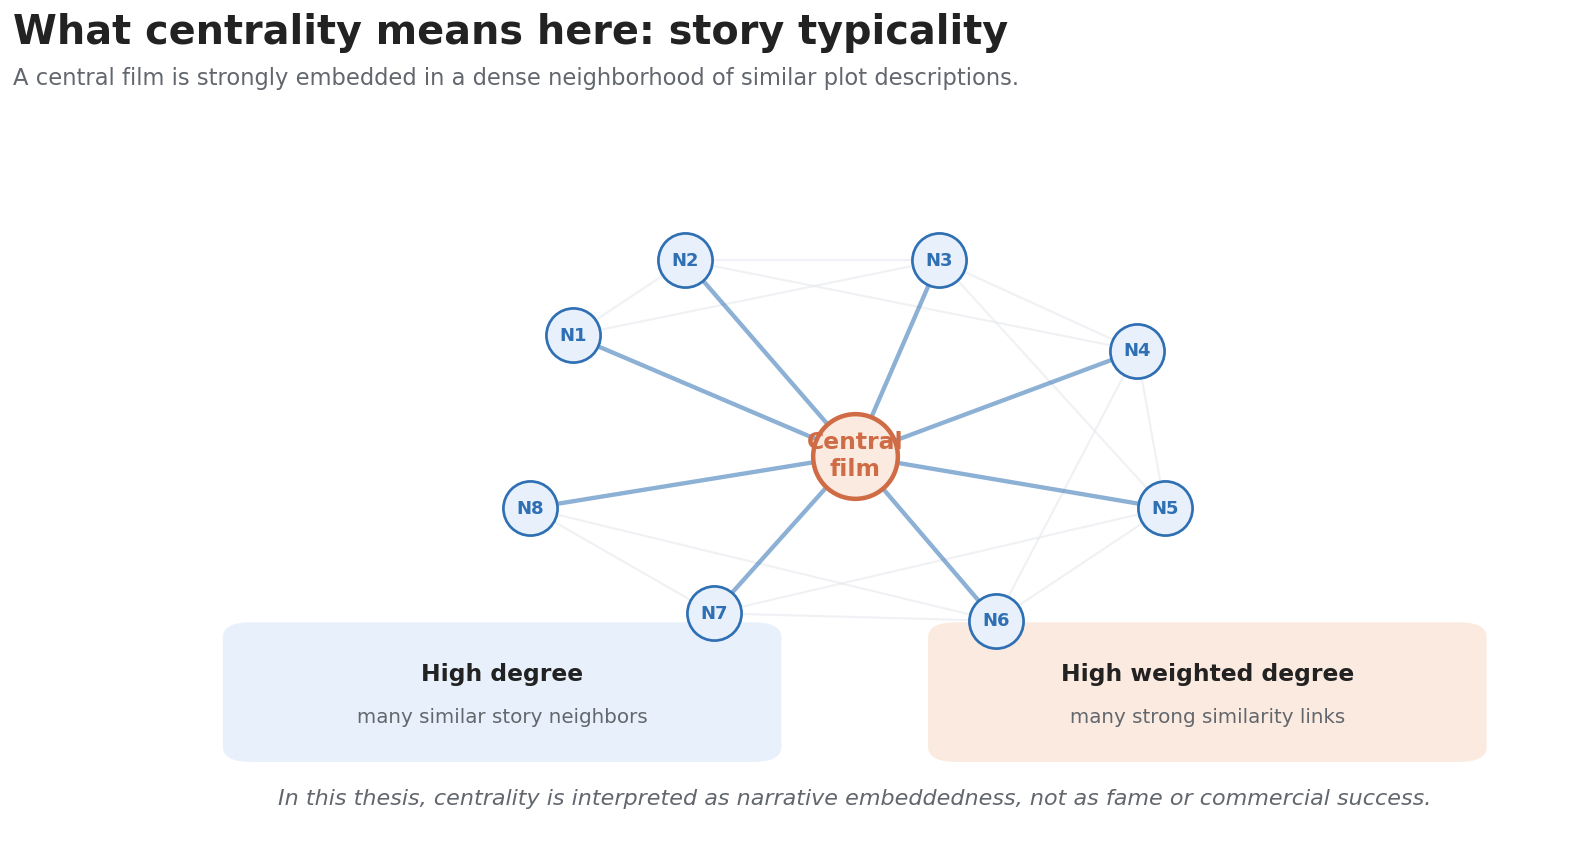

In [5]:

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "What centrality means here: story typicality",
    "A central film is strongly embedded in a dense neighborhood of similar plot descriptions."
)

# Toy dense neighborhood
center = (0.50, 0.52)
neighbors = [
    (0.30, 0.68), (0.38, 0.78), (0.56, 0.78), (0.70, 0.66),
    (0.72, 0.45), (0.60, 0.30), (0.40, 0.31), (0.27, 0.45)
]

# Draw neighbor-neighbor faint links
for i, (x1, y1) in enumerate(neighbors):
    for j, (x2, y2) in enumerate(neighbors):
        if i < j and abs(i-j) <= 2:
            ax.plot([x1, x2], [y1, y2], color=COL["grid"], lw=1.2, alpha=0.55, zorder=1)

# Draw central links
for x, y in neighbors:
    ax.plot([center[0], x], [center[1], y], color=COL["blue"], lw=2.4, alpha=0.55, zorder=2)

# Neighbor nodes
for i, (x, y) in enumerate(neighbors, start=1):
    ax.scatter(x, y, s=900, color=COL["light_blue"], edgecolor=COL["blue"], linewidth=1.5, zorder=3)
    ax.text(x, y, f"N{i}", ha="center", va="center", fontsize=10, fontweight="bold", color=COL["blue"], zorder=4)

# Central node
ax.scatter(center[0], center[1], s=2200, color=COL["light_orange"], edgecolor=COL["orange"], linewidth=2.5, zorder=5)
ax.text(center[0], center[1], "Central\nfilm", ha="center", va="center", fontsize=13, fontweight="bold", color=COL["orange"], zorder=6)

# Explanatory boxes
ax.add_patch(FancyBboxPatch(
    (0.07, 0.13), 0.36, 0.15,
    boxstyle="round,pad=0.018,rounding_size=0.02",
    facecolor=COL["light_blue"],
    edgecolor="none"
))
ax.text(0.25, 0.22, "High degree", ha="center", fontsize=13, fontweight="bold")
ax.text(0.25, 0.165, "many similar story neighbors", ha="center", fontsize=11, color=COL["muted"])

ax.add_patch(FancyBboxPatch(
    (0.57, 0.13), 0.36, 0.15,
    boxstyle="round,pad=0.018,rounding_size=0.02",
    facecolor=COL["light_orange"],
    edgecolor="none"
))
ax.text(0.75, 0.22, "High weighted degree", ha="center", fontsize=13, fontweight="bold")
ax.text(0.75, 0.165, "many strong similarity links", ha="center", fontsize=11, color=COL["muted"])

ax.text(
    0.5, 0.055,
    "In this thesis, centrality is interpreted as narrative embeddedness, not as fame or commercial success.",
    ha="center",
    fontsize=12.3,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_centrality_as_story_typicality.png")
plt.show()


## 5. Figure 2 — Weighted-degree explainer

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/02_weighted_degree_explainer.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/02_weighted_degree_explainer.svg


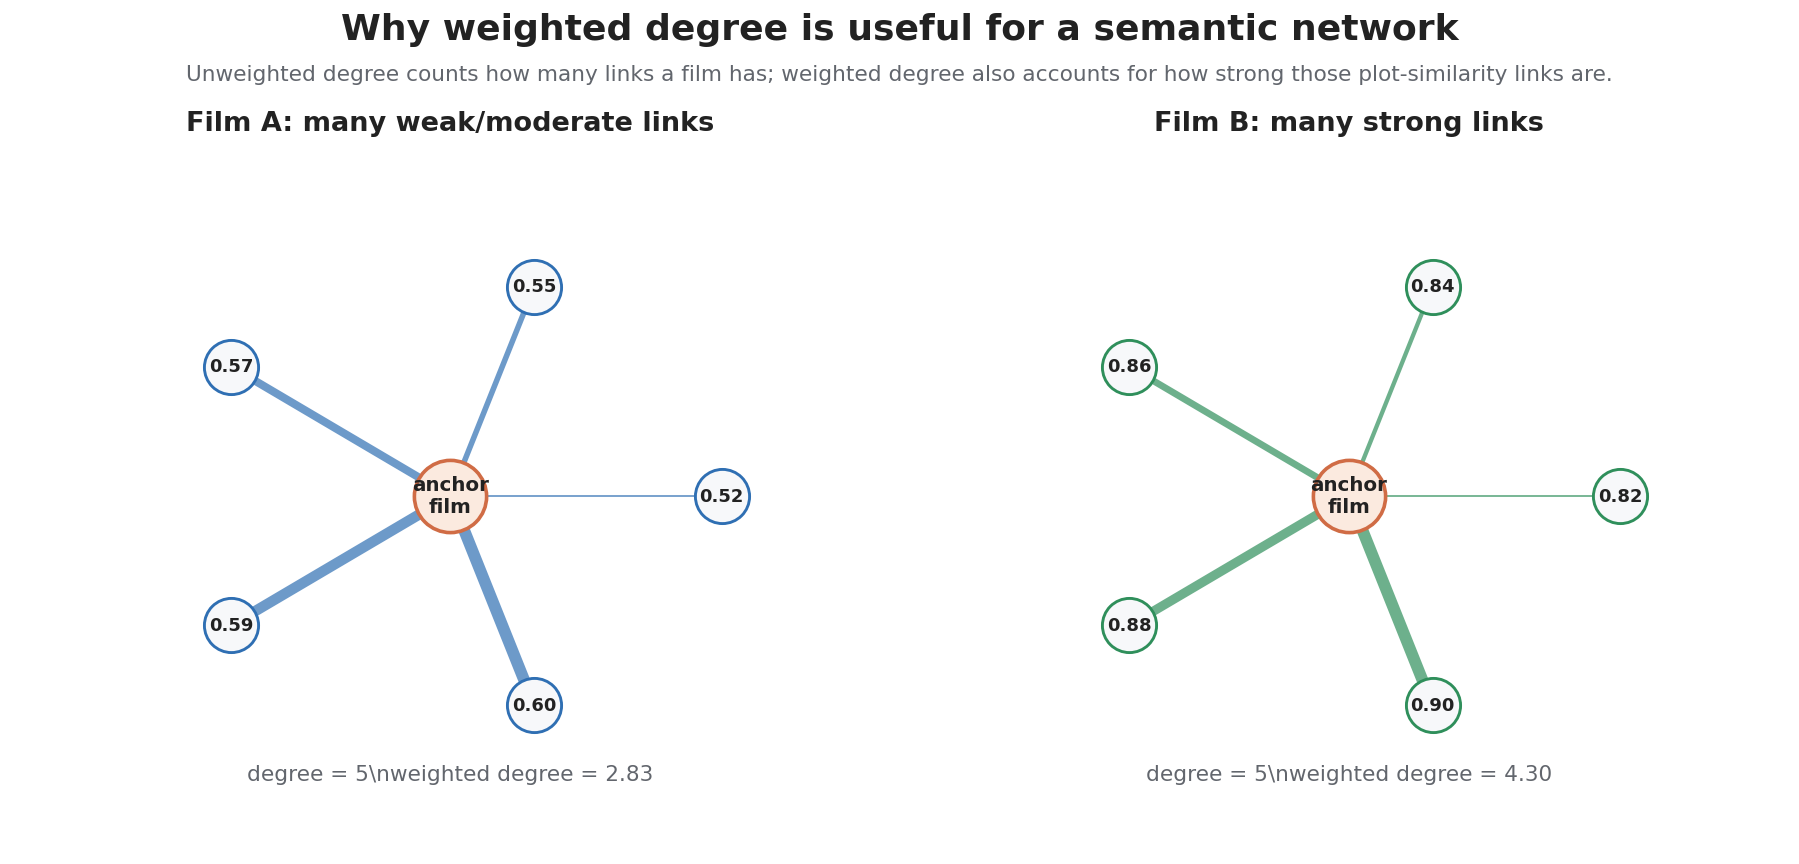

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
fig.suptitle("Why weighted degree is useful for a semantic network", fontsize=20, fontweight="bold", y=1.02)
fig.text(
    0.5, 0.94,
    "Unweighted degree counts how many links a film has; weighted degree also accounts for how strong those plot-similarity links are.",
    ha="center",
    fontsize=12,
    color=COL["muted"]
)

# Two toy examples with same degree but different weights.
toy_sets = [
    ("Film A: many weak/moderate links", [0.52, 0.55, 0.57, 0.59, 0.60], COL["blue"]),
    ("Film B: many strong links", [0.82, 0.84, 0.86, 0.88, 0.90], COL["green"]),
]

for ax, (title, weights, color) in zip(axes, toy_sets):
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    center = (0.50, 0.50)
    angles = np.linspace(0, 2*np.pi, len(weights), endpoint=False)
    radius = 0.31

    ax.scatter(center[0], center[1], s=1600, color=COL["light_orange"], edgecolor=COL["orange"], linewidth=2.0, zorder=5)
    ax.text(center[0], center[1], "anchor\nfilm", ha="center", va="center", fontsize=11, fontweight="bold", zorder=6)

    for i, (w, angle) in enumerate(zip(weights, angles), start=1):
        x = center[0] + radius * np.cos(angle)
        y = center[1] + radius * np.sin(angle)
        lw = 1.0 + 5.5 * ((w - min(weights)) / (max(weights) - min(weights) + 1e-9))
        ax.plot([center[0], x], [center[1], y], color=color, lw=lw, alpha=0.70, zorder=2)
        ax.scatter(x, y, s=900, color=COL["panel"], edgecolor=color, linewidth=1.6, zorder=3)
        ax.text(x, y, f"{w:.2f}", ha="center", va="center", fontsize=10, fontweight="bold", zorder=4)

    degree = len(weights)
    weighted_degree = sum(weights)
    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.text(0.5, 0.10, f"degree = {degree}\\nweighted degree = {weighted_degree:.2f}", ha="center", fontsize=12, color=COL["muted"])

plt.tight_layout()
save_fig(fig, "02_weighted_degree_explainer.png")
plt.show()


## 6. Figure 3 — Weighted-degree distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/03_weighted_degree_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/03_weighted_degree_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/03_weighted_degree_distribution.svg


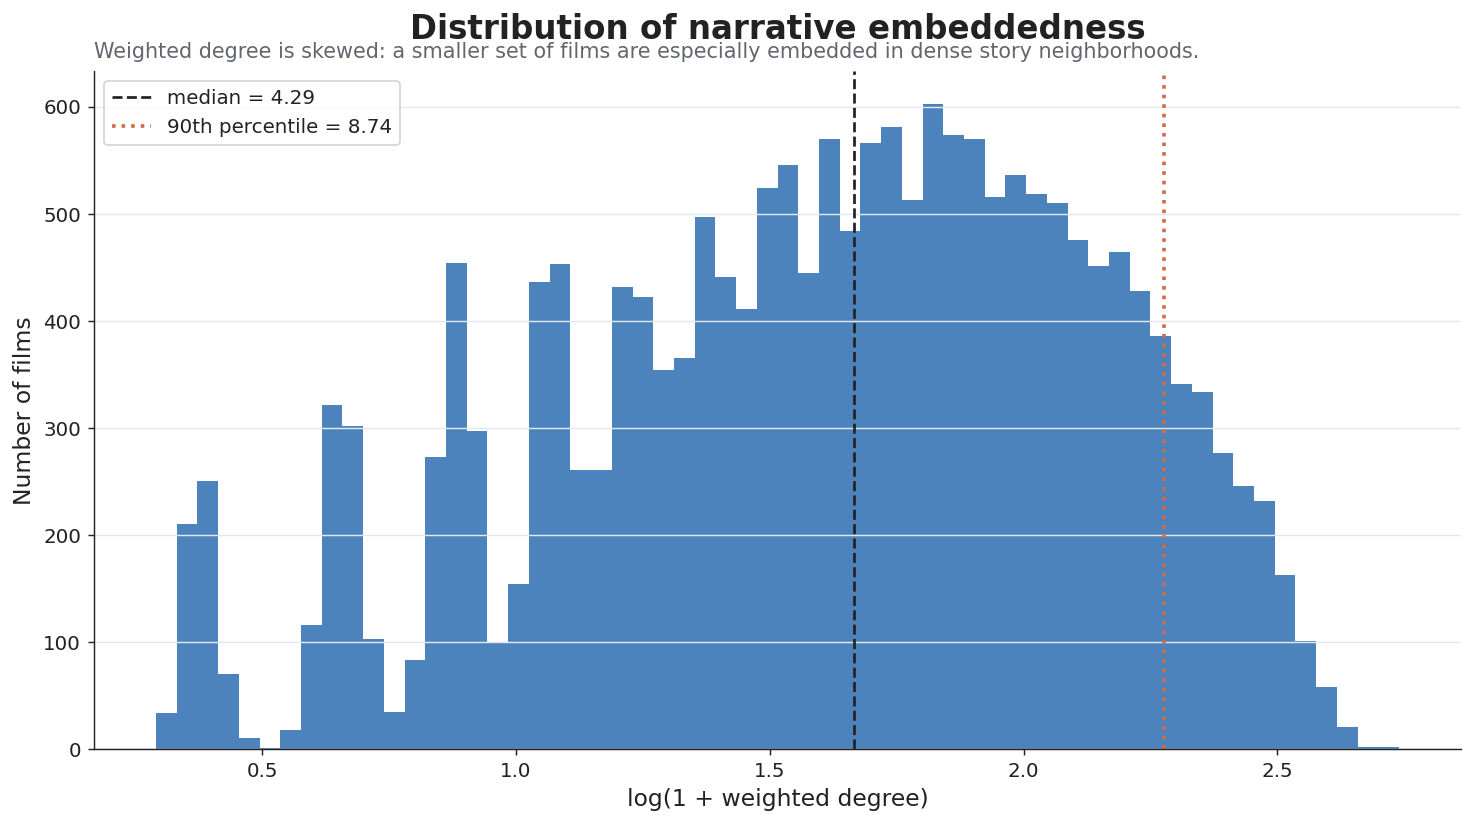

In [7]:

x = central_nodes["centrality_score"].dropna()
x_log = np.log1p(x)

summary = pd.DataFrame({
    "metric": ["n", "min", "median", "mean", "p75", "p90", "p95", "max"],
    "value": [len(x), x.min(), x.median(), x.mean(), x.quantile(.75), x.quantile(.90), x.quantile(.95), x.max()]
})
save_table(summary, "03_weighted_degree_distribution_summary.csv")

fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.hist(x_log, bins=60, color=COL["blue"], alpha=0.86)
ax.axvline(np.log1p(x.median()), color=COL["ink"], ls="--", lw=1.5, label=f"median = {x.median():.2f}")
ax.axvline(np.log1p(x.quantile(.90)), color=COL["orange"], ls=":", lw=2.0, label=f"90th percentile = {x.quantile(.90):.2f}")

ax.set_title("Distribution of narrative embeddedness", pad=18)
ax.text(
    0, 1.02,
    "Weighted degree is skewed: a smaller set of films are especially embedded in dense story neighborhoods.",
    transform=ax.transAxes,
    fontsize=11.5,
    color=COL["muted"]
)
ax.set_xlabel("log(1 + weighted degree)")
ax.set_ylabel("Number of films")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=COL["grid"])
ax.legend()

plt.tight_layout()
save_fig(fig, "03_weighted_degree_distribution.png")
plt.show()


## 7. Figure 4 — Central films by community table

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/04_central_films_by_community_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/04_central_films_by_community_table.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/04_central_films_by_community_table.svg


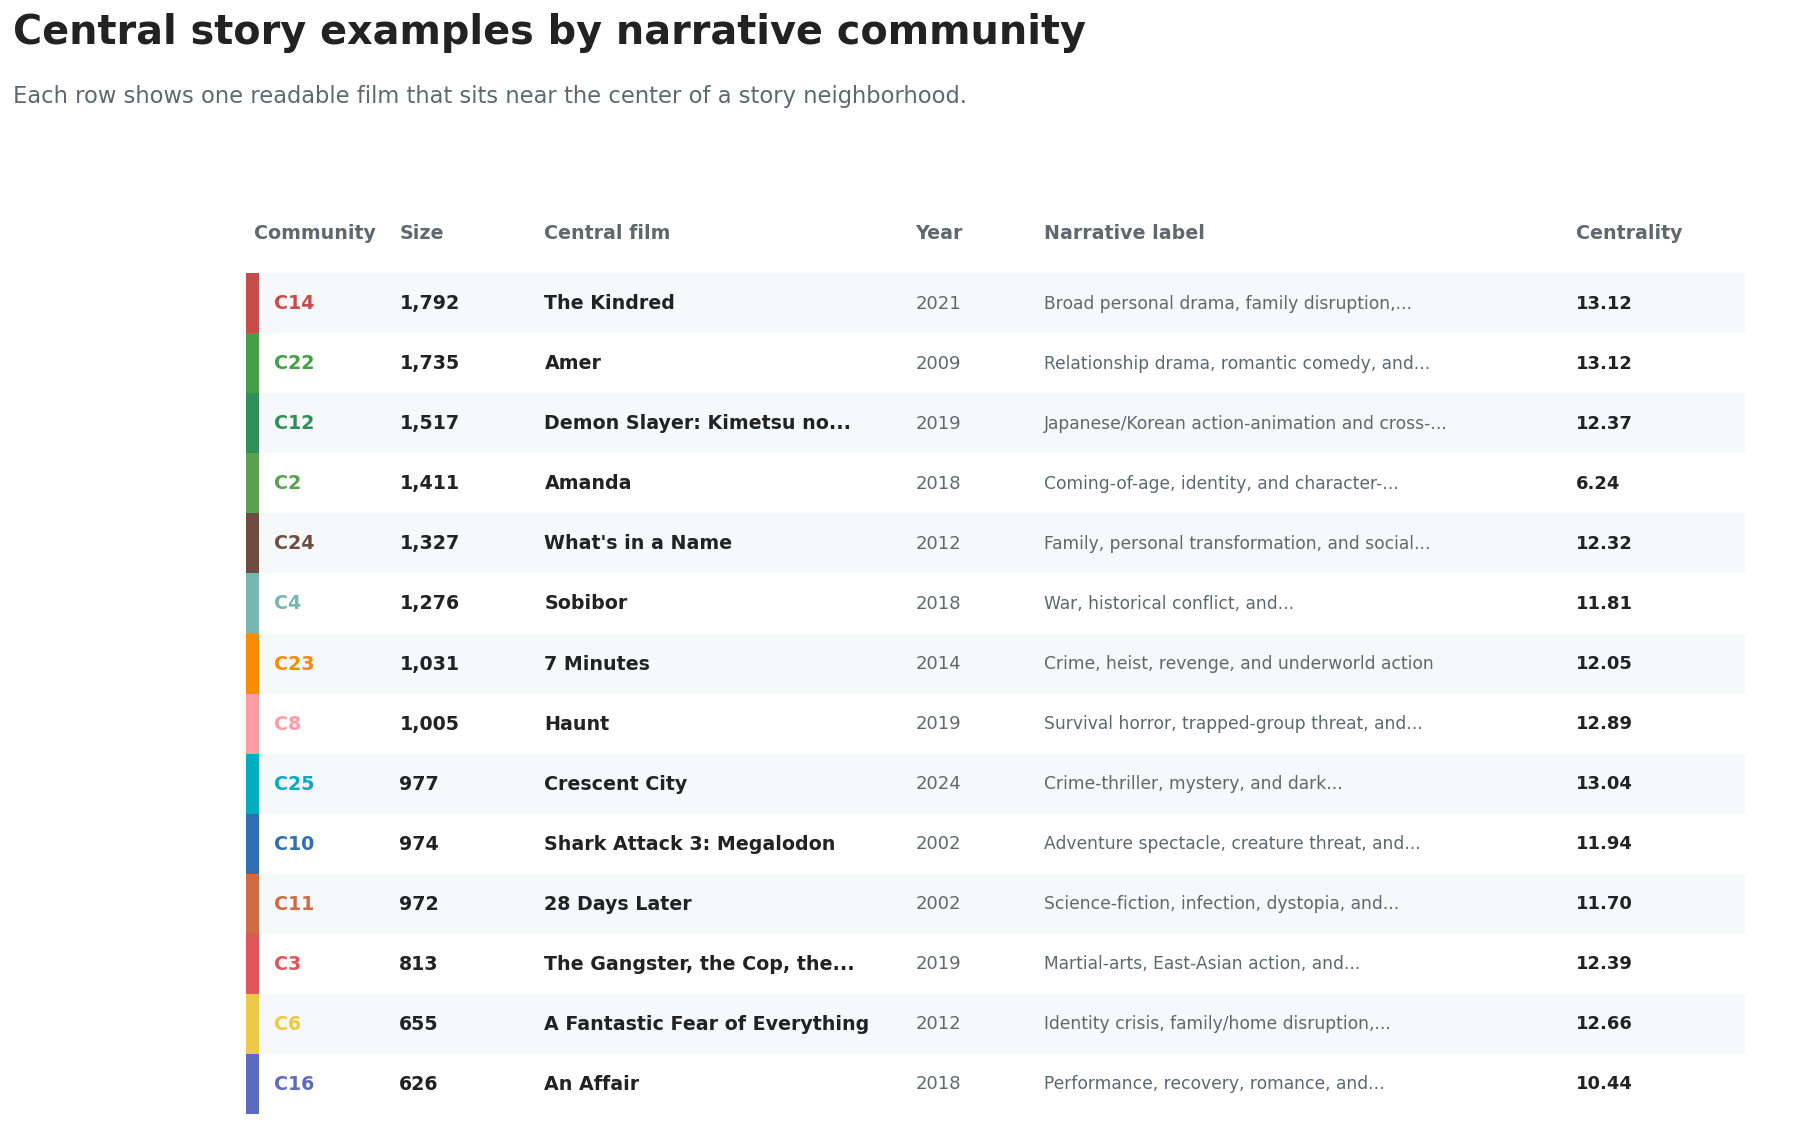

In [8]:

# Use one top central film per major community.
central = central_source.copy()

if "rank_within_community" in central.columns:
    central_one = central.sort_values("rank_within_community").groupby("community_id").head(1)
else:
    central_one = central.sort_values("centrality_score", ascending=False).groupby("community_id").head(1)

# Attach community size and label if missing.
if community_labels is not None:
    size_cols = ["community_id", "n_films"]
    if label_col:
        size_cols.append(label_col)
    cmeta = community_labels[size_cols].drop_duplicates()
    central_one = central_one.merge(cmeta, on="community_id", how="left", suffixes=("", "_meta"))
    if "narrative_label" not in central_one.columns and label_col in central_one.columns:
        central_one["narrative_label"] = central_one[label_col]

central_one = central_one.sort_values("n_films", ascending=False).head(14)

save_table(central_one, "04_central_films_by_community_table.csv")

fig, ax = plt.subplots(figsize=(16, 10))
ax.axis("off")
title_block(
    fig,
    "Central story examples by narrative community",
    "Each row shows one readable film that sits near the center of a story neighborhood.",
    x=0.04,
    y=0.965
)

start_y = 0.84
row_h = 0.060
headers = ["Community", "Size", "Central film", "Year", "Narrative label", "Centrality"]
xs = [0.04, 0.13, 0.22, 0.45, 0.53, 0.86]

for x0, h in zip(xs, headers):
    ax.text(x0, start_y + 0.045, h, transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=COL["muted"])

for i, (_, r) in enumerate(central_one.iterrows()):
    y = start_y - i * row_h
    cid = int(r["community_id"])
    color = community_color(cid)
    bg = COL["panel"] if i % 2 == 0 else "white"
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.010), 0.93, row_h, transform=ax.transAxes, facecolor=bg, edgecolor="none"))
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.010), 0.008, row_h, transform=ax.transAxes, facecolor=color, edgecolor="none"))

    title = clean_title(r.get("title", r.get(title_col, "")))
    year = r.get("release_year", "")
    if pd.notna(year):
        try:
            year = int(year)
        except Exception:
            pass

    ax.text(0.052, y - 0.020, f"C{cid}", transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=color, va="center")
    ax.text(0.13, y - 0.020, fmt_int(r.get("n_films", "")), transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="center")
    ax.text(0.22, y - 0.020, shorten(title, 30), transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="center")
    ax.text(0.45, y - 0.020, str(year), transform=ax.transAxes, fontsize=10.0, color=COL["muted"], va="center")
    ax.text(0.53, y - 0.020, shorten(r.get("narrative_label", ""), 46), transform=ax.transAxes, fontsize=9.5, color=COL["muted"], va="center")
    ax.text(0.86, y - 0.020, fmt_float(r.get("centrality_score", np.nan), 2), transform=ax.transAxes, fontsize=10.0, fontweight="bold", va="center")

save_fig(fig, "04_central_films_by_community_table.png")
plt.show()


## 8. Figure 5 — Central story profile sheets

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C14.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C14.svg


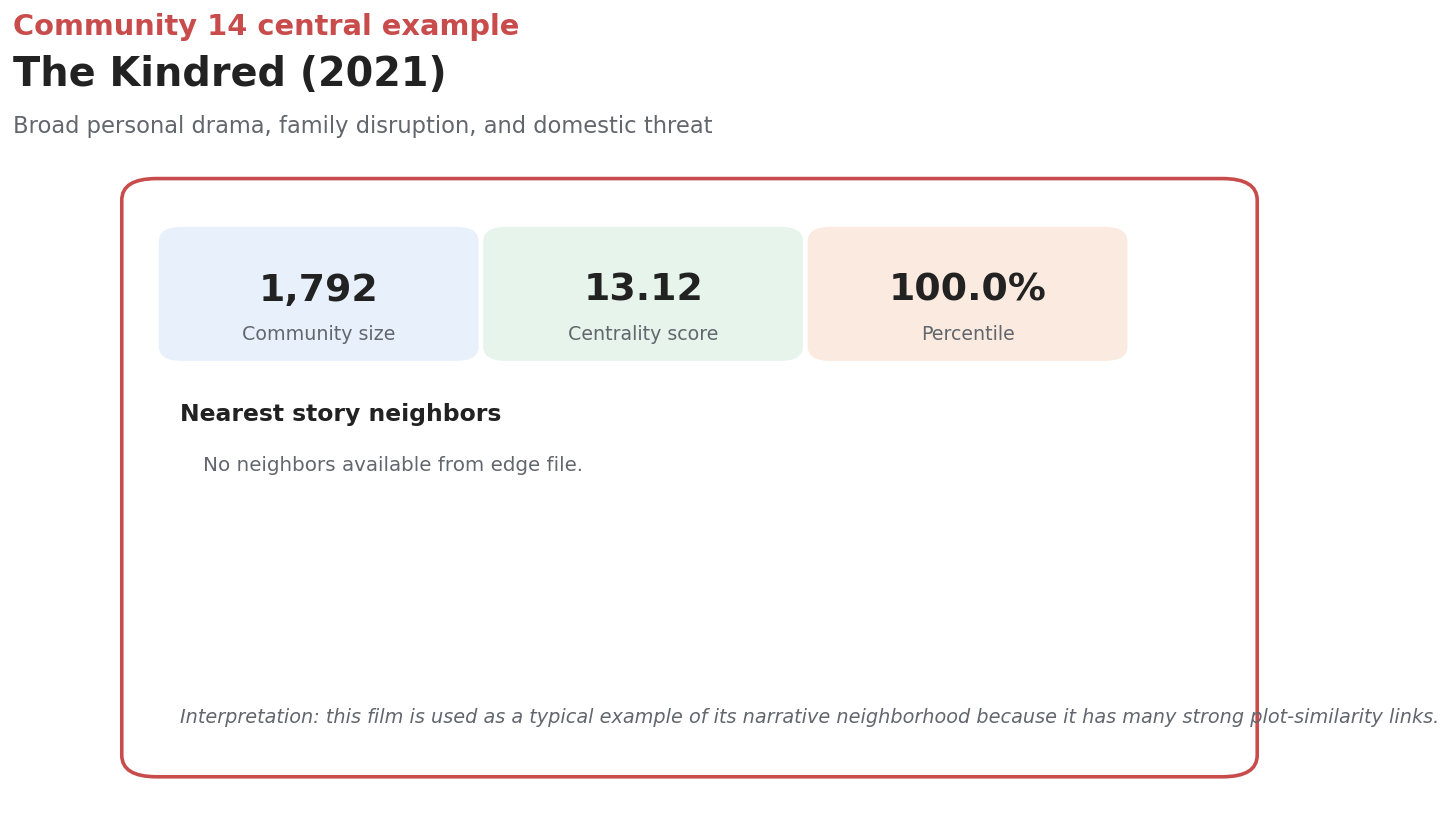

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C22.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C22.svg


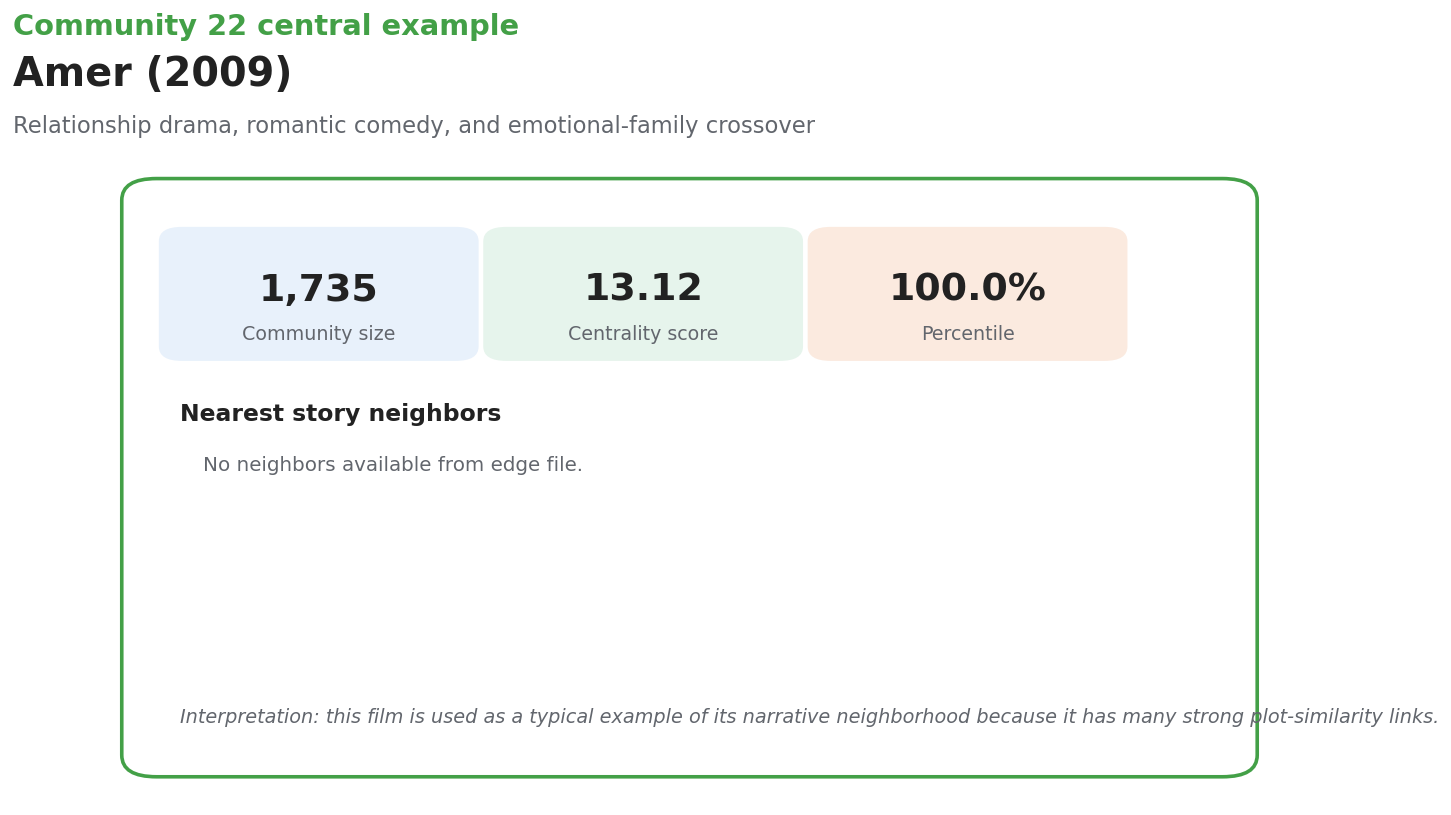

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C12.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C12.svg


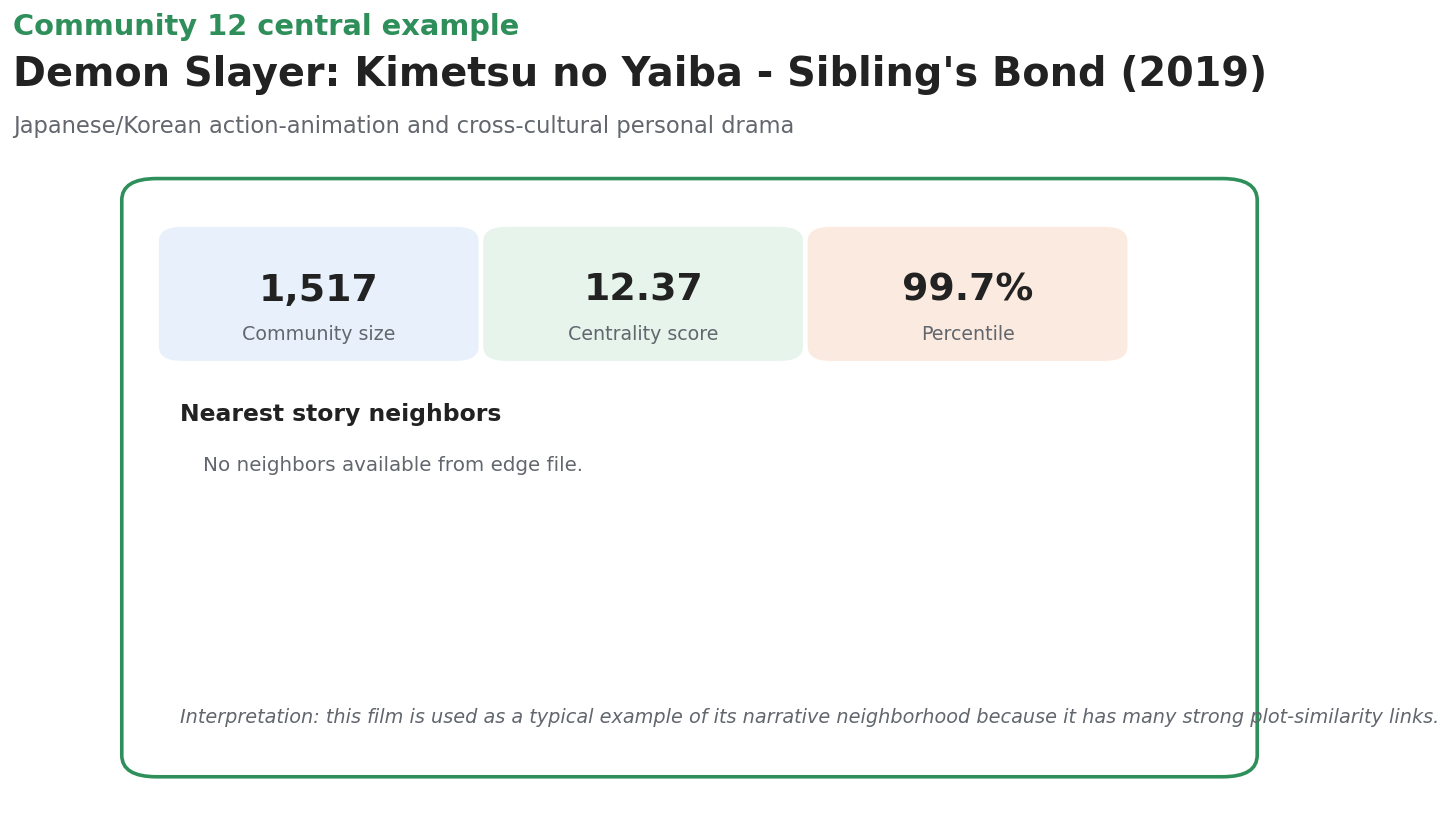

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C02.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C02.svg


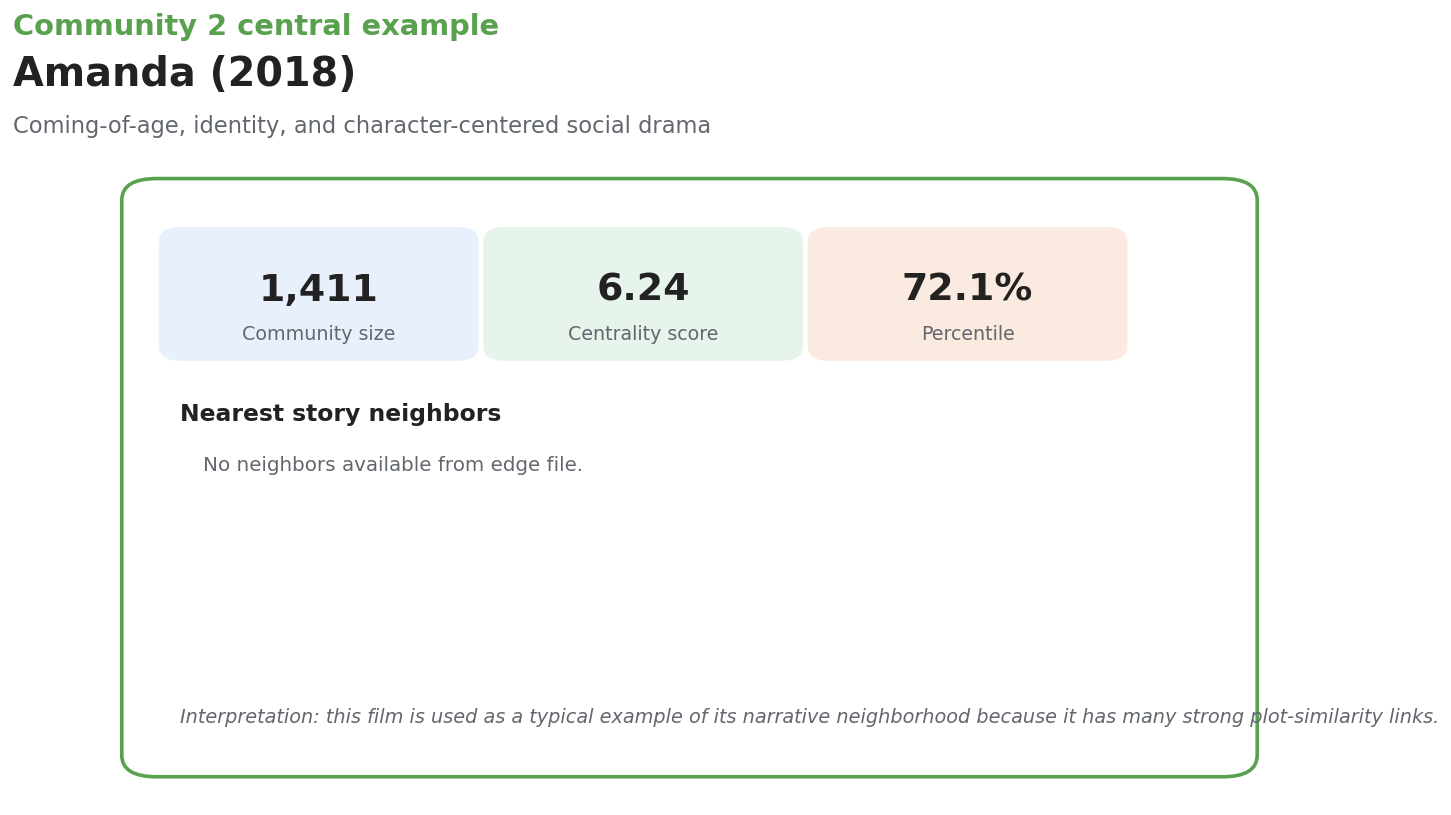

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C24.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C24.svg


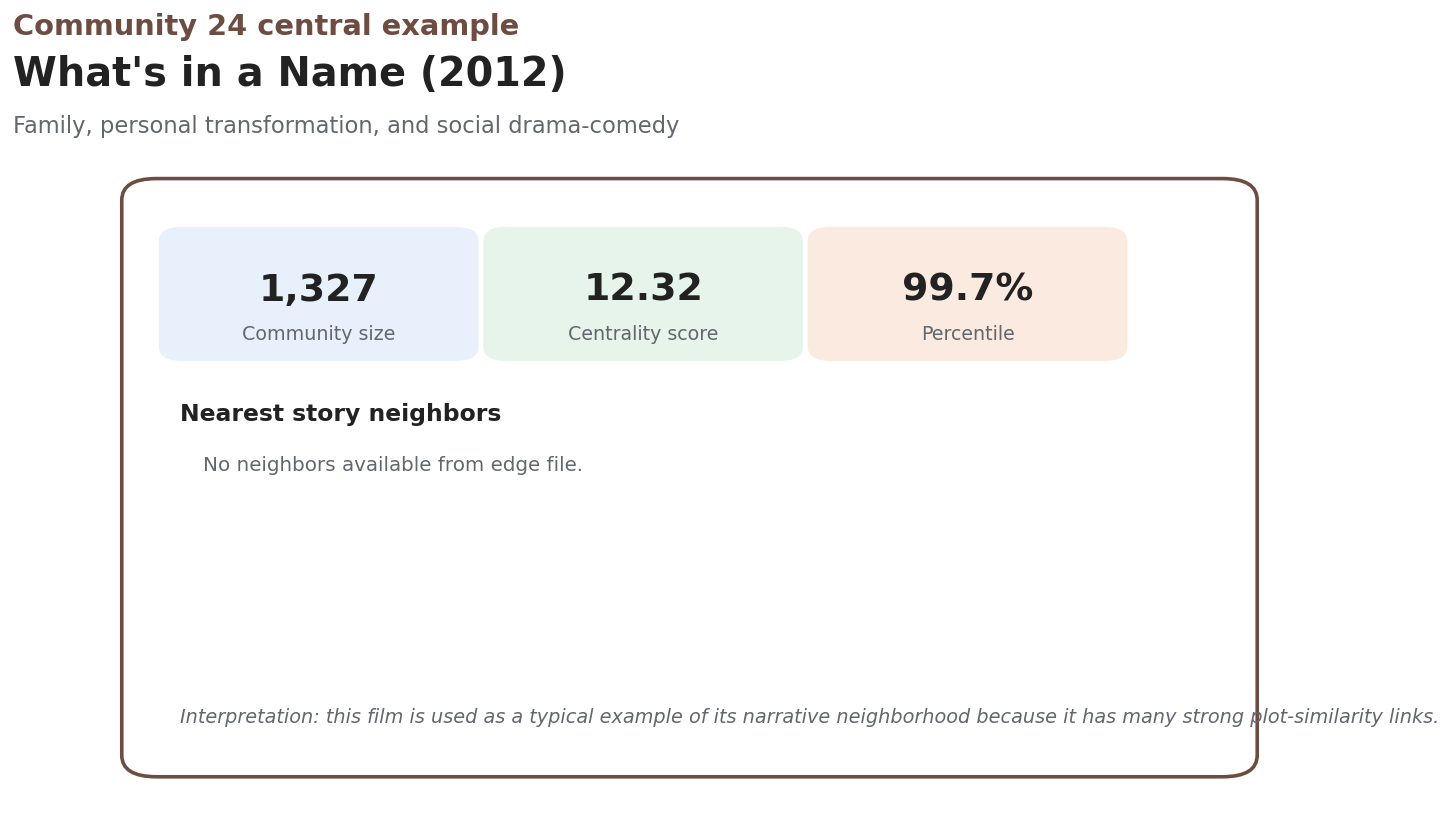

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C04.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/05_central_story_profile_C04.svg


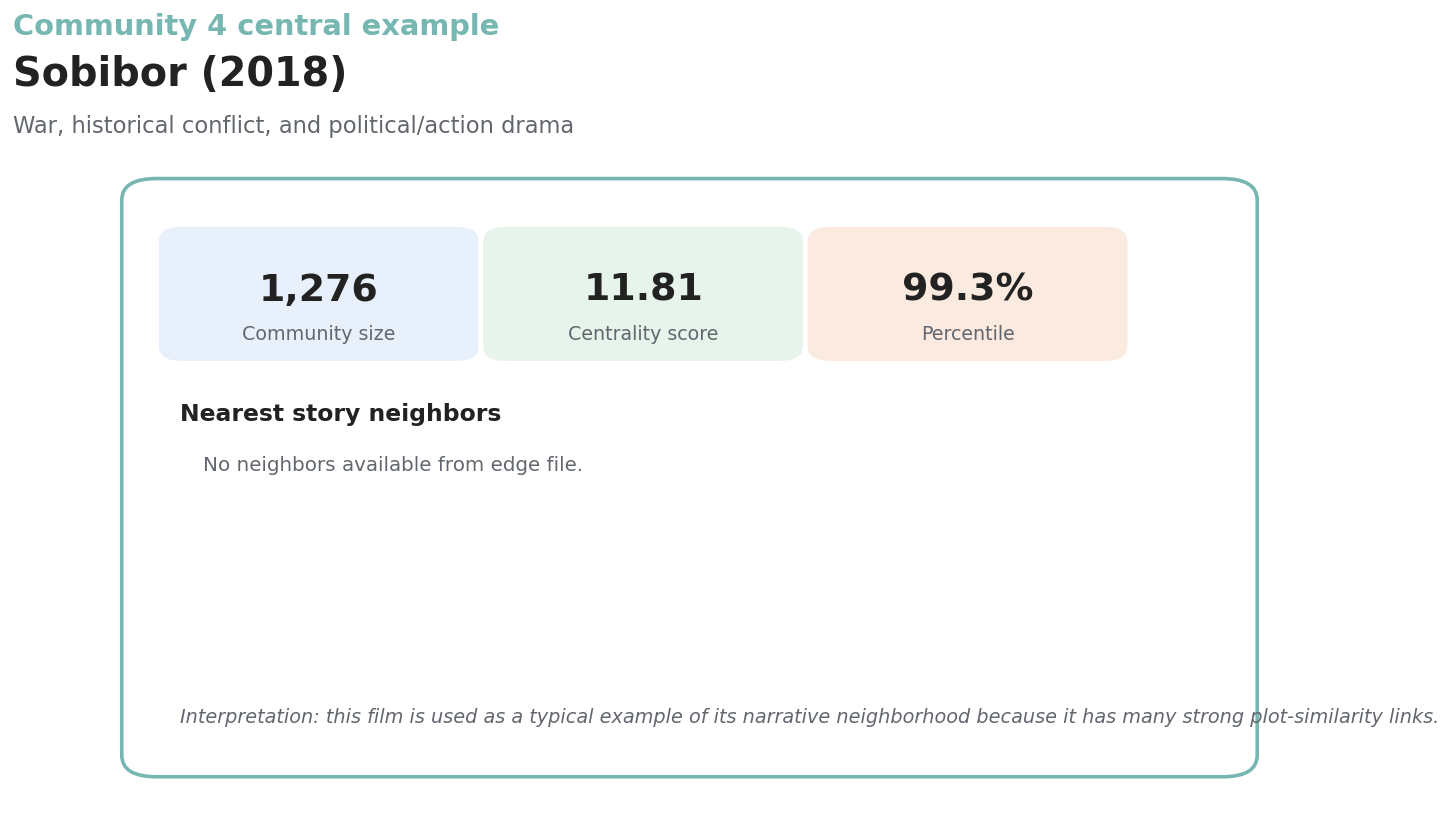

In [9]:

# Individual profile sheets for top 6 communities by size.
profiles = central_one.sort_values("n_films", ascending=False).head(6).copy()

for _, r in profiles.iterrows():
    cid = int(r["community_id"])
    color = community_color(cid)
    node_id = r[node_id_col]
    title = clean_title(r.get("title", r.get(title_col, film_title(node_id) if 'film_title' in globals() else "")))
    year = r.get("release_year", "—")
    try:
        if pd.notna(year):
            year = int(year)
    except Exception:
        pass

    neigh = get_neighbors(node_id, top_n=5)
    label = str(r.get("narrative_label", ""))
    n_films = r.get("n_films", np.nan)
    score = r.get("centrality_score", np.nan)

    fig, ax = plt.subplots(figsize=(11.5, 7.2))
    ax.axis("off")

    fig.text(0.06, 0.93, f"Community {cid} central example", fontsize=16, fontweight="bold", color=color, ha="left")
    fig.text(0.06, 0.875, f"{title} ({year})", fontsize=22, fontweight="bold", color=COL["ink"], ha="left")
    fig.text(0.06, 0.825, wrap_text(label, 85), fontsize=12.5, color=COL["muted"], ha="left")

    # Cards
    card_data = [
        (0.06, "Community size", fmt_int(n_films), COL["light_blue"]),
        (0.34, "Centrality score", fmt_float(score, 2), COL["light_green"]),
        (0.62, "Percentile", f"{float(r.get('centrality_percentile', np.nan))*100:.1f}%" if pd.notna(r.get("centrality_percentile", np.nan)) else "—", COL["light_orange"]),
    ]
    for x0, label_c, value_c, bg in card_data:
        ax.add_patch(FancyBboxPatch(
            (x0, 0.63), 0.24, 0.15,
            boxstyle="round,pad=0.018,rounding_size=0.02",
            facecolor=bg,
            edgecolor="none",
            transform=ax.transAxes
        ))
        ax.text(x0 + 0.12, 0.71, value_c, transform=ax.transAxes, ha="center", va="center", fontsize=21, fontweight="bold")
        ax.text(x0 + 0.12, 0.65, label_c, transform=ax.transAxes, ha="center", va="center", fontsize=10.5, color=COL["muted"])

    # Neighbors
    ax.text(0.06, 0.53, "Nearest story neighbors", transform=ax.transAxes, fontsize=13, fontweight="bold")
    y = 0.46
    if len(neigh):
        for i, (_, nr) in enumerate(neigh.head(5).iterrows(), start=1):
            sim = nr.get("edge_weight", np.nan)
            sim_txt = f"{sim:.3f}" if pd.notna(sim) else "edge"
            ax.text(0.08, y, f"{i}. {shorten(nr['neighbor_title'], 58)} ({nr['neighbor_year']})", transform=ax.transAxes, fontsize=11.0, color=COL["ink"])
            ax.text(0.70, y, f"similarity {sim_txt}", transform=ax.transAxes, fontsize=10.0, color=COL["muted"])
            y -= 0.058
    else:
        ax.text(0.08, y, "No neighbors available from edge file.", transform=ax.transAxes, fontsize=11.0, color=COL["muted"])

    ax.text(
        0.06, 0.11,
        "Interpretation: this film is used as a typical example of its narrative neighborhood because it has many strong plot-similarity links.",
        transform=ax.transAxes,
        fontsize=10.7,
        color=COL["muted"],
        style="italic"
    )

    ax.add_patch(FancyBboxPatch(
        (0.035, 0.06), 0.93, 0.78,
        boxstyle="round,pad=0.025,rounding_size=0.03",
        facecolor="none",
        edgecolor=color,
        linewidth=2.0,
        transform=ax.transAxes
    ))

    save_fig(fig, f"05_central_story_profile_C{cid:02d}.png")
    plt.show()


## 9. Figure 6 — Local neighborhood of selected central films

In [11]:

# Use 3 profile examples. One local ego network per figure.
selected = profiles.head(3).copy()

for _, r in selected.iterrows():
    cid = int(r["community_id"])
    color = community_color(cid)
    node_id = r[node_id_col]
    title = clean_title(r.get("title", r.get(title_col, "")))
    year = r.get("release_year", "—")
    try:
        if pd.notna(year):
            year = int(year)
    except Exception:
        pass

    neigh = get_neighbors(node_id, top_n=8)
    if len(neigh) == 0:
        continue

    save_table(neigh, f"06_local_neighborhood_C{cid:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', title)[:25]}.csv")

    fig, ax = plt.subplots(figsize=(11, 8))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    title_block(
        fig,
        f"Local story neighborhood: {title}",
        "One central film and its strongest plot-neighbor links.",
        x=0.05,
        y=0.965
    )

    center = (0.50, 0.50)
    ax.scatter(center[0], center[1], s=2600, color=COL["light_orange"], edgecolor=color, linewidth=2.7, zorder=5)
    ax.text(center[0], center[1], wrap_text(f"{title}\\n({year})", 18), ha="center", va="center", fontsize=10.5, fontweight="bold", zorder=6)

    n = min(len(neigh), 8)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    radius = 0.33
    weights = neigh["edge_weight"].fillna(neigh["edge_weight"].median()).values[:n]
    wmin, wmax = np.nanmin(weights), np.nanmax(weights)

    for angle, (_, nr), w in zip(angles, neigh.head(n).iterrows(), weights):
        x = center[0] + radius * np.cos(angle)
        y = center[1] + radius * np.sin(angle)
        ncid = nr["neighbor_community"]
        ncolor = community_color(ncid)
        lw = 1.2 + 4.2 * ((w - wmin) / (wmax - wmin + 1e-9))
        ax.plot([center[0], x], [center[1], y], color=ncolor, alpha=0.62, lw=lw, zorder=1)
        ax.scatter(x, y, s=1200, color=COL["panel"], edgecolor=ncolor, linewidth=1.8, zorder=3)
        ax.text(x, y, wrap_text(f"{nr['neighbor_title']}\\n({nr['neighbor_year']})", 18), ha="center", va="center", fontsize=8.7, fontweight="bold", zorder=4)

    ax.text(
        0.50, 0.075,
        "Line thickness reflects similarity weight. This local view is easier to read than a full-network hairball.",
        ha="center",
        fontsize=10.7,
        color=COL["muted"],
        style="italic"
    )

    save_fig(fig, f"06_central_film_local_neighborhood_C{cid:02d}.png")
    plt.show()


## 10. Figure 7 — Centrality by community small multiples

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/07_centrality_by_community_small_multiples.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/07_centrality_by_community_small_multiples.svg


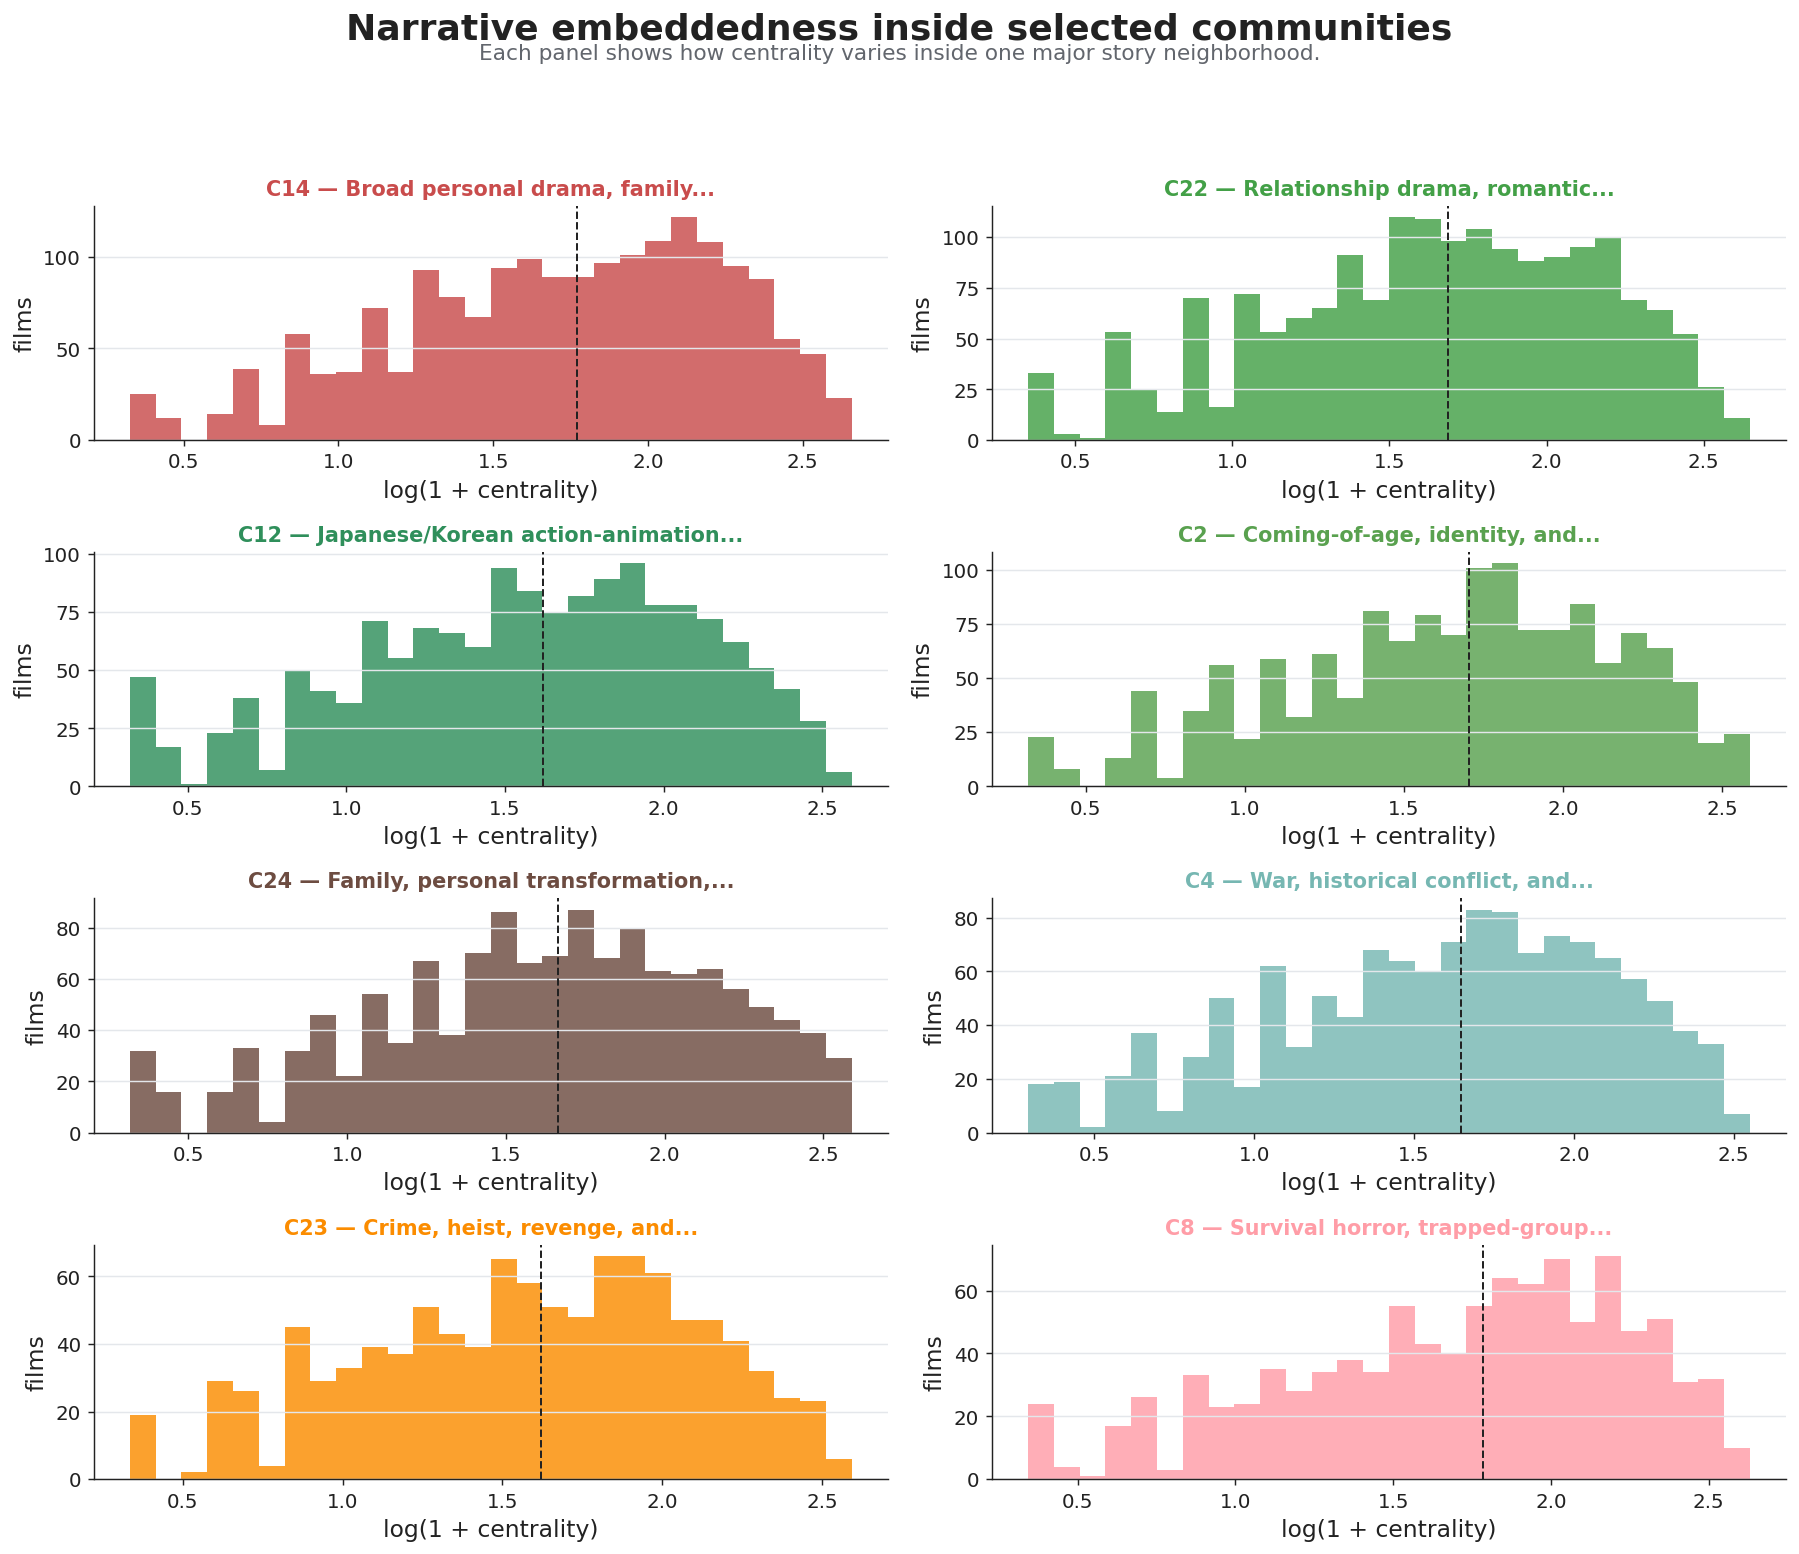

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/07_centrality_by_community_data.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/07_centrality_by_community_data.csv')

In [12]:

# Show distributions for top 8 communities only.
top_comms = central_nodes.groupby("community_id").size().sort_values(ascending=False).head(8).index.tolist()
plot_df = central_nodes[central_nodes["community_id"].isin(top_comms)].copy()

fig, axes = plt.subplots(4, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, cid in zip(axes, top_comms):
    sub = plot_df[plot_df["community_id"] == cid]["centrality_score"].dropna()
    color = community_color(cid)

    ax.hist(np.log1p(sub), bins=28, color=color, alpha=0.82)
    ax.axvline(np.log1p(sub.median()), color=COL["ink"], ls="--", lw=1.1)

    label = ""
    if community_labels is not None:
        hit = community_labels[community_labels["community_id"] == cid]
        if len(hit):
            label = str(hit.iloc[0][label_col])

    ax.set_title(f"C{int(cid)} — {shorten(label, 36)}", fontsize=11.5, fontweight="bold", color=color)
    ax.set_xlabel("log(1 + centrality)")
    ax.set_ylabel("films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])

for ax in axes[len(top_comms):]:
    ax.axis("off")

fig.suptitle("Narrative embeddedness inside selected communities", fontsize=20, fontweight="bold", y=0.995)
fig.text(
    0.5, 0.965,
    "Each panel shows how centrality varies inside one major story neighborhood.",
    ha="center",
    fontsize=12,
    color=COL["muted"]
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, "07_centrality_by_community_small_multiples.png")
plt.show()

save_table(plot_df[[node_id_col, title_col, "community_id", "centrality_score", "centrality_percentile"]], "07_centrality_by_community_data.csv")


## 11. Figure 8 — Centrality interpretation summary

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/08_centrality_interpretation_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/figures/08_centrality_interpretation_summary.svg


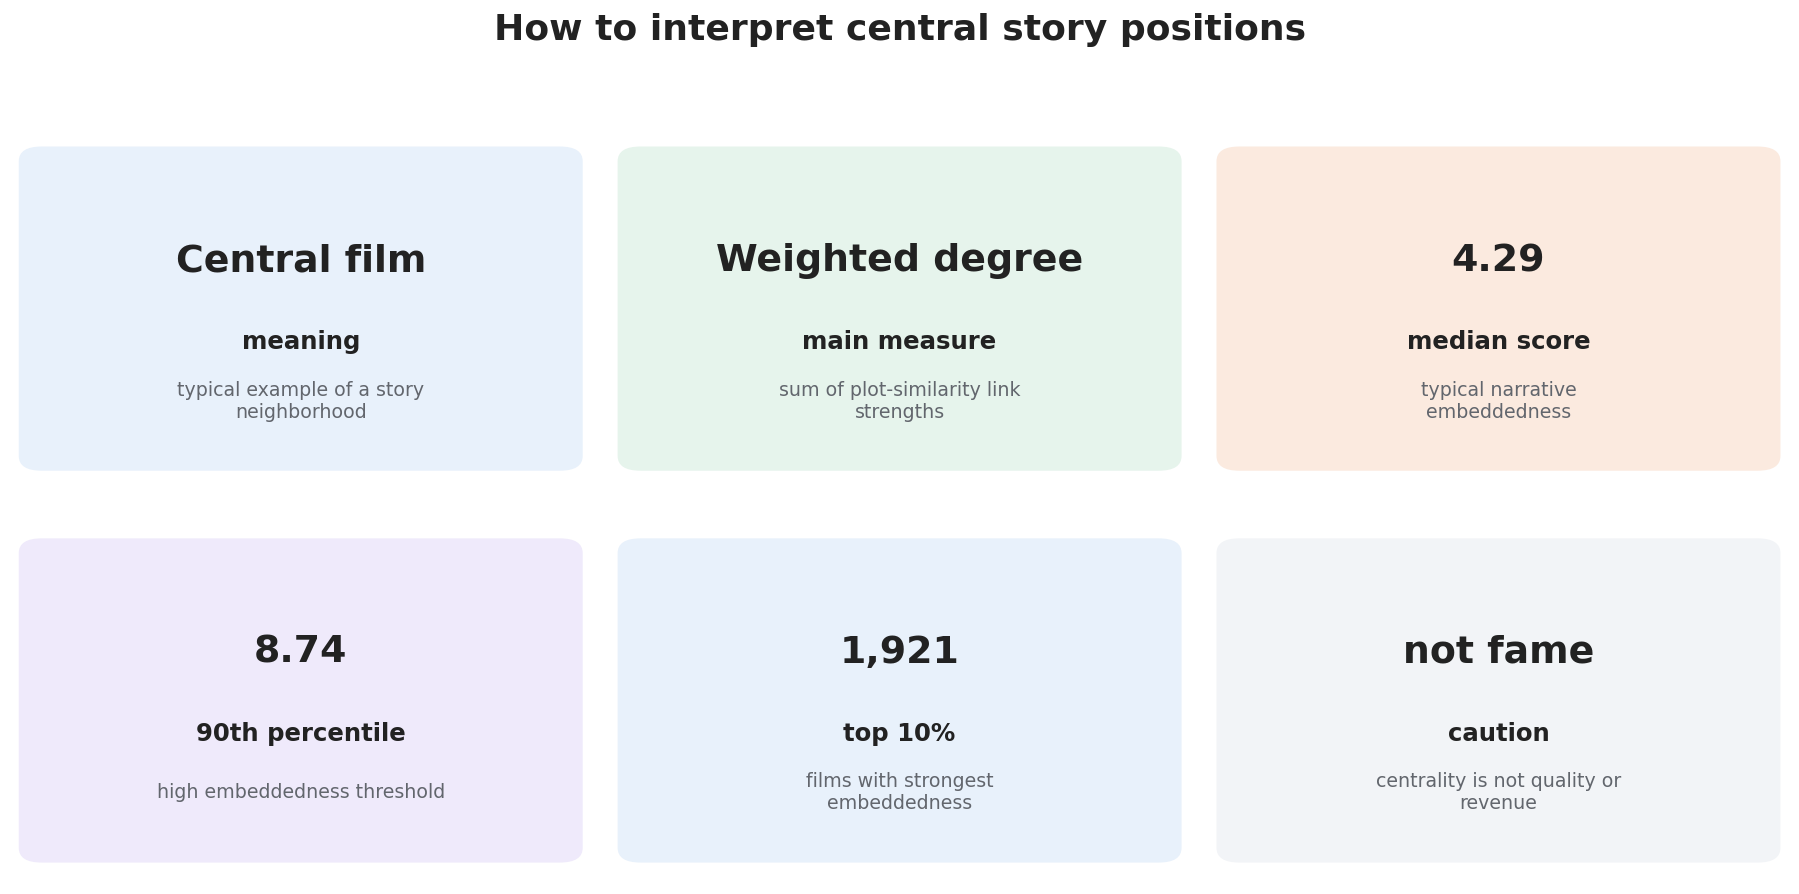

In [13]:

top_pct = (central_nodes["centrality_percentile"] >= 0.90).sum()
median_score = central_nodes["centrality_score"].median()
p90_score = central_nodes["centrality_score"].quantile(0.90)
max_score = central_nodes["centrality_score"].max()

cards = [
    ("Central film", "meaning", "typical example of a story neighborhood", COL["light_blue"]),
    ("Weighted degree", "main measure", "sum of plot-similarity link strengths", COL["light_green"]),
    (fmt_float(median_score, 2), "median score", "typical narrative embeddedness", COL["light_orange"]),
    (fmt_float(p90_score, 2), "90th percentile", "high embeddedness threshold", COL["light_purple"]),
    (fmt_int(top_pct), "top 10%", "films with strongest embeddedness", COL["light_blue"]),
    ("not fame", "caution", "centrality is not quality or revenue", COL["light_gray"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=21, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, wrap_text(subtitle, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("How to interpret central story positions", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "08_centrality_interpretation_summary.png")
plt.show()


## 12. Export interpretation note

In [14]:

note = f"""
Brick 5 — Central story positions interpretation note

This section should appear after the narrative-community section and before the bridging-position section.

Main message:
A central film in this thesis is a film strongly embedded in a dense neighborhood of similar plot descriptions. Centrality is interpreted as story typicality or narrative embeddedness, not as fame, quality, revenue, or star power.

Recommended main thesis figures:
1. 01_centrality_as_story_typicality.png
2. 02_weighted_degree_explainer.png
3. 04_central_films_by_community_table.png
4. Selected 05_central_story_profile_CXX.png profile sheets
5. Selected 06_central_film_local_neighborhood_CXX.png local neighborhoods

Recommended appendix/supporting figures:
1. 03_weighted_degree_distribution.png
2. 07_centrality_by_community_small_multiples.png
3. 08_centrality_interpretation_summary.png

Important wording:
Weighted degree is used as a measure of local narrative embeddedness because it accounts for both the number of plot-neighbor links and the strength of those similarity links.
""".strip()

write_text(note, "brick_05_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/text/brick_05_interpretation_note.txt
Brick 5 — Central story positions interpretation note

This section should appear after the narrative-community section and before the bridging-position section.

Main message:
A central film in this thesis is a film strongly embedded in a dense neighborhood of similar plot descriptions. Centrality is interpreted as story typicality or narrative embeddedness, not as fame, quality, revenue, or star power.

Recommended main thesis figures:
1. 01_centrality_as_story_typicality.png
2. 02_weighted_degree_explainer.png
3. 04_central_films_by_community_table.png
4. Selected 05_central_story_profile_CXX.png profile sheets
5. Selected 06_central_film_local_neighborhood_CXX.png local neighborhoods

Recommended appendix/supporting figures:
1. 03_weighted_degree_distribution.png
2. 07_centrality_by_community_small_multiples.png
3. 08_centrality_interpretation_su

## 13. Output check

In [15]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_centrality_as_story_typicality.png
- 02_weighted_degree_explainer.png
- 03_weighted_degree_distribution.png
- 04_central_films_by_community_table.png
- 05_central_story_profile_C02.png
- 05_central_story_profile_C04.png
- 05_central_story_profile_C12.png
- 05_central_story_profile_C14.png
- 05_central_story_profile_C22.png
- 05_central_story_profile_C24.png
- 07_centrality_by_community_small_multiples.png
- 08_centrality_interpretation_summary.png

Tables:
- 00_central_source_for_figures.csv
- 00_centrality_node_diagnostics.csv
- 03_weighted_degree_distribution_summary.csv
- 04_central_films_by_community_table.csv
- 07_centrality_by_community_data.csv

Text:
- brick_05_interpretation_note.txt
